In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import gc
import pandas as pd

========================================================================================================================================================================

                                원본 ppg 를 시작마커(8888) 이후, 종료 5분전 시점에서 자르는 작업 수행, 원본 csv 에서 [:,7] > 8번째 열에서 ppg를 갖고옴

========================================================================================================================================================================

In [4]:
all_dicts = {}
sub_dicts = {'frame' : 0 , 'time' : 0.0}
video_dir = '/nasdata2/2yhy/CNA_ours_IRB/raw_frame_files/CNA_member_raw_frames'  #비디오 원본
people_video = ['A001_20250609','A002_20250609','A004_20250610','A005_20250611','A006_20250611','A007_20250612','A008_20250612','B001_20250623',
        'B002_20250623','B003_20250624','B004_20250624','B005_20250625','B008_20250627','C001_20250701','C002_20250703','C003_20250702']

for i in range(len(people_video)) :
    subject_num = i
    vp1 = os.path.join(video_dir,people_video[subject_num]) # 원본비디오루트

    sub_dicts['frame'] = (len(os.listdir(vp1)))
    sub_dicts['time'] = (np.round(np.array(len(os.listdir(vp1))/30),3))
    all_dicts[people_video[subject_num]]= sub_dicts
    sub_dicts = {'frame' : 0 , 'time' : 0.0}

df_vd = pd.DataFrame(all_dicts)
display(df_vd)


,A001_20250609,A002_20250609,A004_20250610,A005_20250611,A006_20250611,A007_20250612,A008_20250612,B001_20250623,B002_20250623,B003_20250624,B004_20250624,B005_20250625,B008_20250627,C001_20250701,C002_20250703,C003_20250702
frame,116727.0,123226.000,123421.000,129274.000,113290.000,129591.0,125805.0,126047.000,128635.000,115142.000,115634.000,136330.000,113771.000,117504.0,126464.000,116410.000
time,3890.9,4107.533,4114.033,4309.133,3776.333,4319.7,4193.5,4201.567,4287.833,3838.067,3854.467,4544.333,3792.367,3916.8,4215.467,3880.333


In [8]:
ppg_list = sorted([x.replace('_20', '_') for x in people_video])
ppg_list_csv = sorted([y +'.csv' for y in ppg_list ])
df_vd.columns = ppg_list

ppg_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_cut_final'
reraw_ppg_root = '/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw' # 해당 폴더 프레임수 확인 8888이후의 데이터개수를 셈

for idx in tqdm(range(len(ppg_list_csv))) :

    subject_num = idx
    subject_id = ppg_list[idx]

    ppg_root = os.path.join(reraw_ppg_root, ppg_list_csv[subject_num])
    print(ppg_root)

    ppg_1 = pd.read_csv(ppg_root)
    target_indices = ppg_1.index[ppg_1.iloc[:, -1] == 8888.0].tolist()
    start_num = target_indices[-1] + 1 # 8888이후 첫번쨰 인덱스

    goal_time = df_vd[ppg_list[subject_num]]['time'] ##영상의 시간

    ppg_last_index = int((goal_time * 500) + start_num)

    print(f'subejct : {ppg_list[idx]} , 영상시간 : {goal_time}, ppg자른후 시간 : {(ppg_last_index - start_num -1) / 500}')

    ppg_cut_last = ppg_1.iloc[ start_num : ppg_last_index , 7] #8열이 ppg 신호

    saved = os.path.join(ppg_save_dir,ppg_list_csv[subject_num] ) 

    ppg_cut_last.to_csv(saved, index=False)



  0%|          | 0/16 [00:00<?, ?it/s]

/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw/A001_250609.csv
subejct : A001_250609 , 영상시간 : 3890.9, ppg자른후 시간 : 3890.898


  6%|▋         | 1/16 [00:03<00:57,  3.84s/it]

/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw/A002_250609.csv
subejct : A002_250609 , 영상시간 : 4107.533, ppg자른후 시간 : 4107.53


 12%|█▎        | 2/16 [00:23<03:07, 13.39s/it]

...

/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw/B001_250623.csv
subejct : B001_250623 , 영상시간 : 4201.567, ppg자른후 시간 : 4201.564


 50%|█████     | 8/16 [02:21<02:33, 19.19s/it]

/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw/B002_250623.csv
subejct : B002_250623 , 영상시간 : 4287.833, ppg자른후 시간 : 4287.83


 56%|█████▋    | 9/16 [02:40<02:14, 19.19s/it]

/nasdata2/2yhy/CNA_ours_IRB/edited/final_report_ppg/raw_data_link/CNA_members/csv/ppg_raw/B003_250624.csv


In [24]:
from scipy import signal
video_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/' #비디오 원본
people_video = sorted([f for f in os.listdir(video_dir)])
ppg_list = [x.replace('_20', '_') for x in people_video]
ppg_list_csv = [y +'.csv' for y in ppg_list ]
ppg_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_last_5mtruncated'
saved = os.path.join(ppg_save_dir,ppg_list_csv[3]) 
aa = pd.read_csv(saved)
aa = aa.to_numpy()
aa_n = signal.resample(aa, int(aa.shape[0]*(30/500)))

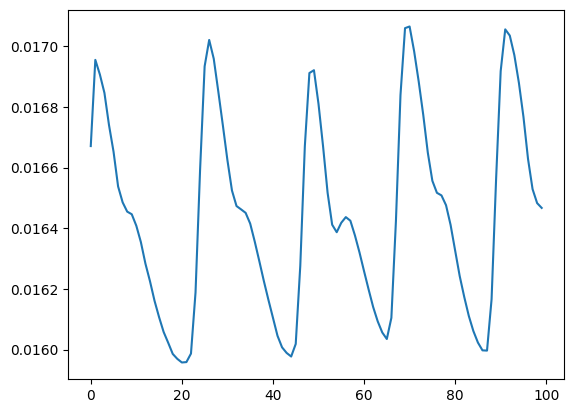

In [29]:
aa_n.shape
plt.plot(aa_n[:100])

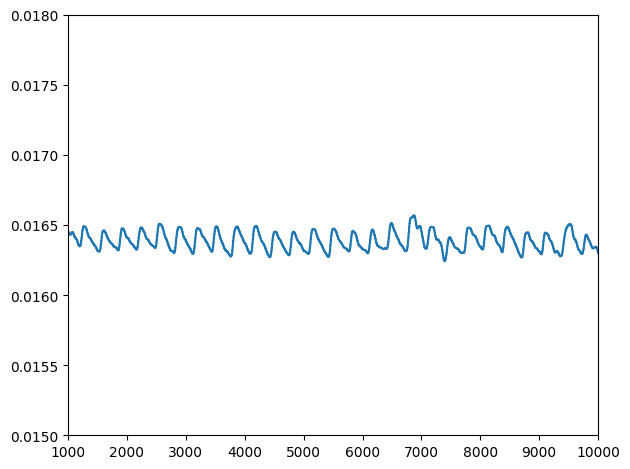

In [50]:
p_t = ppg_1.iloc[:,7]
plt.xlim(1000,10000)
plt.ylim(0.015,0.018)
plt.plot(p_t)
plt.tight_layout() # 그래프 요소 간의 간격을 자동으로 조절
plt.show()